# Suomenkielinen työpaja
## Tee tähän tiedostoon suomenkielinen työpaja 
Voit katsoa mallia muista työpajoista tarvittaessa. 
Nimeä tämä tiedosto uudelleen fi_työpajan_nimi.ipynb
Varmista että README.ipynb tiedostossa on tiedostonimet ja tiedot oikein!

## Binääri

In [1]:
# Muuntaa luvun binääriksi
luku = int(input("Anna kokonaisluku: "))

binaari = bin(luku)[2:]

print(f"Luku {luku} binäärimuodossa on: {binaari}")

# Muuntaa binäärin luvuksi
binaari = input("Anna binääriluku: ")

luku = int(binaari, 2)

print(f"Binääriluku {binaari} kokonaislukuna on: {luku}")


Luku 10 binäärimuodossa on: 1010
Binääriluku 00110011 kokonaislukuna on: 51


## Blochin pallo

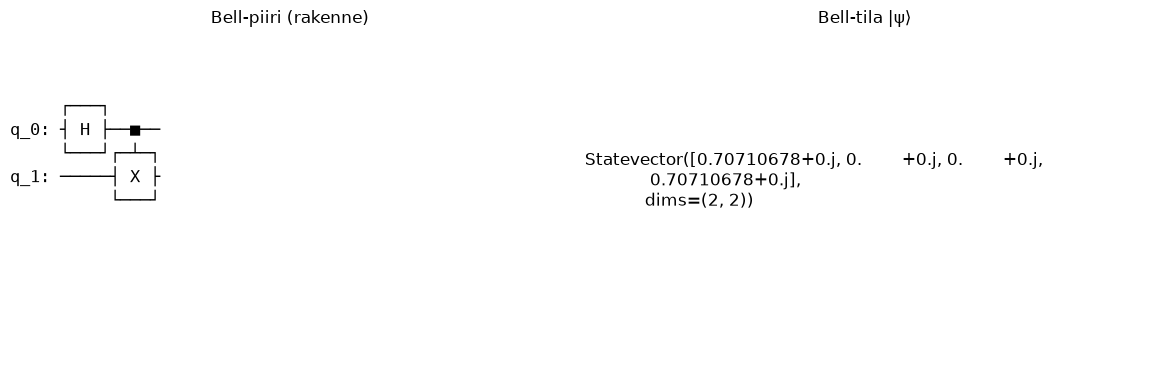

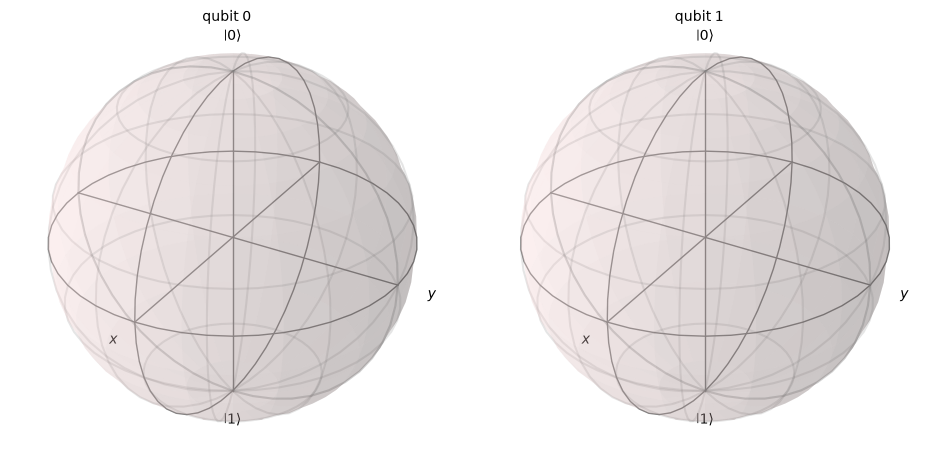

In [2]:
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector

# Tämä on kvanttipiiri, joka rakentaa Bell-tilan:
#
# |Φ+> = (|00> + |11>) / √2
#
# Idea:
# - H luo superposition
# - CNOT tekee korrelaation (lomittaa qubitit)

qc = QuantumCircuit(2)

qc.h(0)     # Hadamard: tekee q0:sta superposition
qc.cx(0,1)  # CNOT: sitoo q0:n ja q1:n yhteen

# Statevector kertoo koko systeemin tilan ennen mittausta.
#
# Tämä EI ole klassinen “joko 00 tai 11”,
# vaan superpositio:
#
# |ψ⟩ = (|00⟩ + |11⟩) / √2

state = Statevector.from_instruction(qc)

bloch_fig = plot_bloch_multivector(state)

# Tässä tehdään kaksi näkymää:
#
# Vasen:
# - kvanttipiiri (miten tila rakennetaan)
#
# Oikea:
# - statevector (mitä tila on matemaattisesti)


fig, ax = plt.subplots(1, 2, figsize=(12,4))

# PIIRI

ax[0].axis("off")
ax[0].set_title("Bell-piiri (rakenne)")

# Piirin ASCII-esitys
ax[0].text(
    0, 0.5,
    str(qc.draw()),
    family="monospace",
    fontsize=12
)

# STATEVECTOR
# Sisältää kaikki mahdolliset tilat yhtä aikaa, mutta eri amplitudeilla
# Kun taas klassinen bitti on joko 0 tai 1

ax[1].axis("off")
ax[1].set_title("Bell-tila |ψ⟩")

# Näytetään kvanttitilan vektori
ax[1].text(
    0, 0.5,
    str(state),
    fontsize=12
)

plt.tight_layout()
plt.show()


# Tämä avaa erillisen kuvan:
# - jokainen qubit Bloch-pallolla
# - lomittuminen näkyy epäsuorasti:
# - yksittäiset pallot eivät ole “puhdasta suuntaa”


bloch_fig


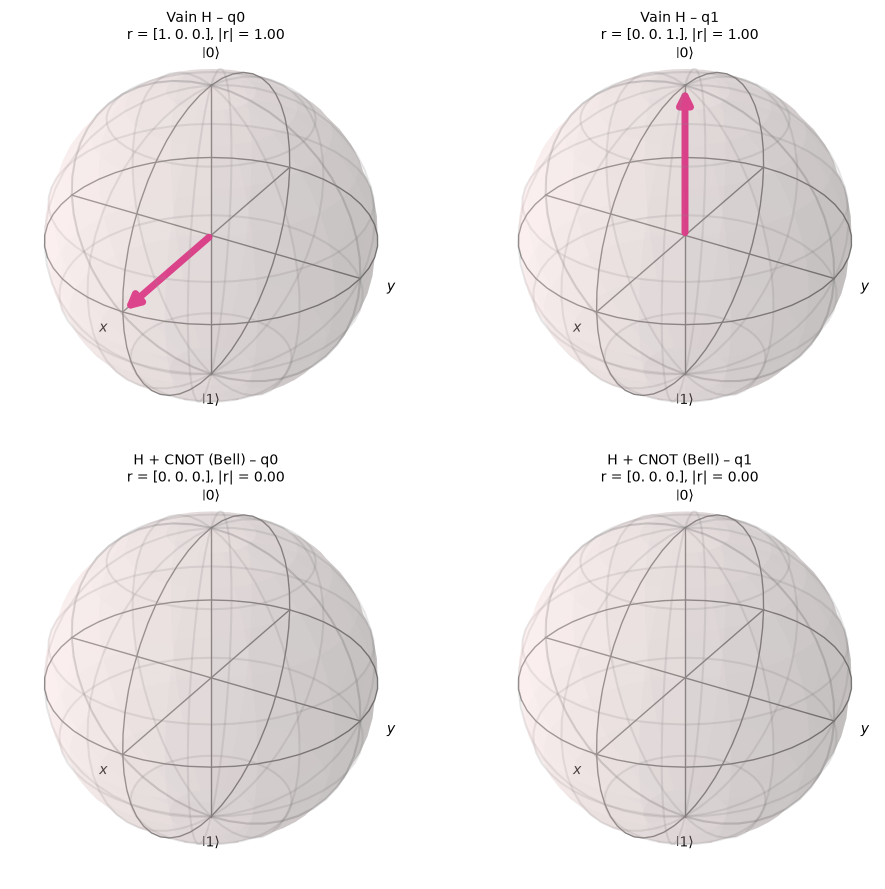

In [3]:
import numpy as np
from qiskit.quantum_info import partial_trace, Pauli
from qiskit.visualization import plot_bloch_vector

def bloch_vector(rho):
    # r = (<X>, <Y>, <Z>) yksittäiselle qubitille
    return [float(np.real(rho.expectation_value(Pauli(p)))) for p in "XYZ"]

# Vertailu: pelkkä H (ei lomittumista) vs. H + CNOT (Bell-tila)
qc_h = QuantumCircuit(2)
qc_h.h(0)

states = {
    "Vain H": Statevector.from_instruction(qc_h),
    "H + CNOT (Bell)": state,
}

fig = plt.figure(figsize=(10, 9))
for row, (name, s) in enumerate(states.items()):
    for q in range(2):
        rho = partial_trace(s, [1 - q])   # jäljitetään toinen qubit pois
        r = bloch_vector(rho)
        ax = fig.add_subplot(2, 2, row * 2 + q + 1, projection="3d")
        plot_bloch_vector(
            r, ax=ax,
            title=f"{name} – q{q}\nr = {np.round(r, 2)}, |r| = {np.linalg.norm(r):.2f}",
        )
plt.tight_layout()
plt.show()


### Portit

In [5]:
#X-portti kääntää kubitin 0 --> 1 ja 1 --> 0 (kvanttinen NOT)

from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = Aer.get_backend('qasm_simulator')

qc = QuantumCircuit(1,1) #lähtötilanne on aina 0

qc.x(0)        # X-portti
qc.measure(0,0)

result = sim.run(qc, shots=1000).result()
counts = result.get_counts()

print("X-portti tulos:", counts)
plot_histogram(counts)
plt.show()

# Hadamard-portti ei ole satunnaistaja, vaan lineaarinen muutos.
from qiskit import QuantumCircuit
from qiskit_aer import Aer

sim = Aer.get_backend('qasm_simulator')

qc = QuantumCircuit(1,1)

qc.h(0)        # Hadamard-portti
qc.measure(0,0)

result = sim.run(qc, shots=1000).result()
print("H-portti:", result.get_counts())


# Z-portti ei muuta mittausta suoraan, vaan se muuttaa kvanttivaihetta, joka näkyy vasta kun tilat interferoivat.
from qiskit import QuantumCircuit
from qiskit_aer import Aer

sim = Aer.get_backend('qasm_simulator')

def run(name, qc):
    result = sim.run(qc, shots=1000).result()
    print(name, result.get_counts())

# ilman Z
qc1 = QuantumCircuit(1,1)
qc1.h(0)
qc1.h(0)
qc1.measure(0,0)

# Z mukana, ajattele aaltoja
qc2 = QuantumCircuit(1,1)
qc2.h(0)                  # jakaa aallon kahteen suuntaan
qc2.z(0)                  # kääntää yhden aallon "ylösalaisin"
qc2.h(0)                  # yhdistää aallot takaisin
qc2.measure(0,0)

run("Ei Z", qc1)
run("Z mukana", qc2)


X-portti tulos: {'1': 1000}
H-portti: {'1': 536, '0': 464}
Ei Z {'0': 1000}
Z mukana {'1': 1000}


### Bellin tilat

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from sympy import nsimplify, simplify
from ipywidgets import interact, Dropdown


# -----------------------------
# STATEVECTOR FORMATOINTI
# -----------------------------
def format_amp(amp):
    val = nsimplify(amp, tolerance=1e-10)  # EI rational=True
    val = simplify(val)

    # pakotetaan siisti √2-muoto Bell-tiloille
    if abs(abs(amp) - 1/np.sqrt(2)) < 1e-8:
        return "1/sqrt(2)" if amp.real > 0 else "-1/sqrt(2)"

    return val


def print_state(state):
    labels = ["00", "01", "10", "11"]
    for amp, label in zip(state.data, labels):
        print(f"|{label}> : {format_amp(amp)}")


# -----------------------------
# BELL-TILAT
# -----------------------------
def bell_state(name):

    qc = QuantumCircuit(2)

    if name in ["Φ⁺", "Φ⁻"]:
        qc.h(0)
        qc.cx(0, 1)

    if name == "Φ⁻":
        qc.z(0)

    if name in ["Ψ⁺", "Ψ⁻"]:
        qc.h(0)
        qc.cx(0, 1)
        qc.x(1)

    if name == "Ψ⁻":
        qc.z(0)

    state = Statevector.from_instruction(qc)
    return qc, state


# -----------------------------
# HEATMAP
# -----------------------------
def plot_heatmap(state):

    probs = state.probabilities_dict()

    mat = np.array([
        [probs.get("00", 0), probs.get("01", 0)],
        [probs.get("10", 0), probs.get("11", 0)]
    ])

    plt.imshow(mat, cmap="viridis", vmin=0, vmax=1)
    plt.title("Korrelaatioheatmap")

    plt.xticks([0,1], ["A=0", "A=1"])
    plt.yticks([0,1], ["B=0", "B=1"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, f"{mat[i,j]:.2f}",
                     ha="center", va="center", color="white")

    plt.show()


# -----------------------------
# DEMO
# -----------------------------
def demo(state_name):

    qc, state = bell_state(state_name)

    print("\n====================")
    print("BELL-TILA:", state_name)
    print("====================")

    print("\nKVANTTIPIIRI")
    print(qc.draw())

    print("\nSTATEVECTOR")
    print_state(state)

    print("\nHEATMAP")
    plot_heatmap(state)


# -----------------------------
# INTERAKTIIVINEN VALITSIN
# -----------------------------
interact(
    demo,
    state_name=Dropdown(
        options=["Φ⁺", "Φ⁻", "Ψ⁺", "Ψ⁻"],
        value="Φ⁺",
        description="Bell"
    )
)
print("""
Hadamard-portti (H)
-avaa kvanttitilan
-tekee 0 ja 1 yhtä todennäköisiä
-mahdollistaa superposition

CNOT-portti
-jos kontrolli (0) = 1 --> kääntää kohteen.
-jos kontrolli = 0 --> ei muutosta.
-ainoa tapa luoda lomittuminen

Z-portti
-peilaa vain signaalin vaiheen.
-mahdollistaa superpositiot
""")


### 2x2 tila avaruus

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_histogram,
    plot_bloch_multivector
)
from qiskit_aer import AerSimulator

import numpy as np
import matplotlib.pyplot as plt

classic = np.array([
    [0.5, 0.0],
    [0.0, 0.5]
])

quantum = np.array([
    [1/np.sqrt(2), 0],
    [0, 1/np.sqrt(2)]
])

fig, ax = plt.subplots(1, 2, figsize=(10,4))

# ---------------------------------------------------
# Klassinen korrelaatio
# ---------------------------------------------------

ax[0].imshow(np.ones((2,2)), cmap="gray", vmin=0, vmax=1)

ax[0].set_title("Klassinen korrelaatio")

for i in range(2):
    for j in range(2):

        ax[0].text(
            j,
            i,
            f"{classic[i,j]:.1f}",
            ha="center",
            va="center",
            fontsize=16,
            color="black"
        )

# ---------------------------------------------------
# Lomittunut Bellin-tila
# ---------------------------------------------------

ax[1].imshow(np.ones((2,2)), cmap="gray", vmin=0, vmax=1)

ax[1].set_title("Lomittuminen")

for i in range(2):
    for j in range(2):

        ax[1].text(
            j,
            i,
            f"{quantum[i,j]:.2f}",
            ha="center",
            va="center",
            fontsize=16,
            color="black"
        )

for a in ax:

    a.set_xticks([0,1])
    a.set_yticks([0,1])

    a.set_xticklabels(["A = 0", "A = 1"])
    a.set_yticklabels(["B = 0", "B = 1"])

plt.tight_layout()
plt.show()

print("""
Klassinen korrelaatio:
- systeemi on joko 00 tai 11
- todennäköisyydet ovat suoraan 0.5 ja 0.5

Lomittuminen:
|Φ+> = (|00> + |11>) / √2

0.71 = 1 / √2

Todennäköisyys = amplitudi²

0.5 ≈ 0.71^2
""")
plt.show()
print("""Jos mittaat ensimmäisen kubitin:
      Saat 0 --> Koko tila romahtaa tilaan 00
      Saat 1 --> Koko tila romahtaa tilaan 11
Tämä on korrelaatio.

Tämä pätee sekä klassiseen korrelaatioon, että lomittumiseenm, mutta eri syystä. 

Klassinen korrelaatio: Ennen mittausta jompikumpi tila on jo olemassa ja mittaus paljastaa sen.
Lomittuminen: Ennen mittausta on superpositio ja tila syntyy mittauksessa.
lomittumisen voi ajatella, jos tiedetään, että on musta ja valkoinen paperi ja laitat molemmat eri laatikoihin joita ei näe ja avaa toisen laatikon, jos musta --> valkoinen toisessa""")


### Mittaus ja romahdus

In [ ]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector


# ----------------------------
# Pretty state formatting
# ----------------------------
def format_state(state):
    vec = state.data
    n = int(np.log2(len(vec)))

    out = []
    for i, amp in enumerate(vec):
        if abs(amp) > 1e-10:
            label = format(i, f"0{n}b")

            # siistit muodot
            if np.isclose(abs(amp), 1/np.sqrt(2)):
                amp_str = "1/√2"
            elif np.isclose(abs(amp), 1):
                amp_str = "1"
            else:
                amp_str = f"{amp.real:.2f}"

            out.append(f"{amp_str} |{label}>")

    return "\n".join(out)


# ----------------------------
# 1. H-portti
# ----------------------------
def step_1_h():
    print("\n======================")
    print("VAIHE 1: H-PORTTI")
    print("======================")

    qc = QuantumCircuit(1)
    qc.h(0)

    print(qc.draw())

    state = Statevector.from_instruction(qc)

    print("\nSTATEVECTOR:")
    print(format_state(state))

    return state



# 2. Mittaus (ennen romahdusta)

def step_2_measure_circuit():
    print("\n======================")
    print("VAIHE 2: MITTAUSPIIRI")
    print("======================")

    qc = QuantumCircuit(1, 1)
    qc.h(0)
    qc.measure(0, 0)

    print(qc.draw())

    return qc



# 3. Romahdus

def step_3_collapse(state):
    print("\n======================")
    print("VAIHE 3: ROMAHDUS")
    print("======================")

    probs = state.probabilities_dict()

    outcome = np.random.choice(
        list(probs.keys()),
        p=list(probs.values())
    )

    collapsed = Statevector.from_label(outcome)

    print("MITTAUSTULOS:", outcome)

    print("\nROMAHTANUT TILA:")
    print(format_state(collapsed))


# ----------------------------
# RUN ALL STEPS
# ----------------------------
def run_demo():
    state = step_1_h()
    step_2_measure_circuit()
    step_3_collapse(state)


run_demo()
# MITTAUS:
# Mittaus tarkoittaa sitä, että kvanttitila “pakotetaan” yhdeksi selkeäksi vastaukseksi: 0 tai 1.
#
# Ennen mittausta kubitti voi olla superpositiossa:
#   esim. (|0> + |1>) / √2
#
# Mittauksessa:
# - Mitataan tulos todennäköisyyksien mukaan
# - Superpositio ei enää näy mittauksen jälkeen


# ROMAHDUS:
# Romahdus tarkoittaa sitä hetkeä, kun superpositio katoaa.
#
# Esimerkki:
#   ennen: (|0> + |1>) / √2
#   jälkeen: |0>  TAI  |1>
#
# Kaikki muut mahdollisuudet “katoavat” mittauksen jälkeen.
# Jäljelle jää vain yksi lopullinen tila.


# INTUITIO:
# Ajattele kubittia kuin kolikkoa ilmassa:
# - ennen mittausta: se ei ole kruuna eikä klaava (se on “molempia”)
# - mittauksessa: kolikko putoaa maahan
# - jälkeen: näet vain yhden tuloksen
